# Intelligent Agents: Reflex-Based Agents for GridHunt (Multi-agent Environment)

Student Name: Đức Lương

I have used the following AI tools: Claude (Anthropic) — used to help implement and debug the hunter agent functions and to draft the experiment/analysis code.

I understand that my submission needs to be my own work: DL


## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

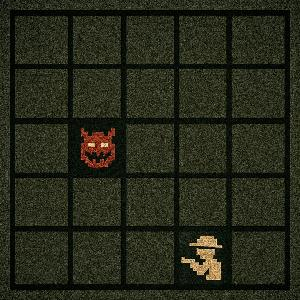

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and several hunter agents and the monster agent move around in the arena. A hunter catches the monster if she/he moves on the same square the monster currently occupies. The hunters compete fow who catches the monster first. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunters are randomly placed in the arena environment. The hunters and the monster
    can move around, but cannot leave the arena. Since there are three agents involved, this is a competitive multi-agent environment.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena and the location of the monster.  

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [1]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_1_agent_function, hunter_2_agent_function, monster_agent_function, n = 30, max_steps = 100, visualize = False, animation = False):
    """
    Simulate an arena where two hunter agent tries to catch a monster agent.

    Parameters:
    hunter_1_agent_function and hunter_2_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_1_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_1_pos, monster_pos):
        hunter_1_pos = np.random.randint(0, n-1, size=2)
    hunter_2_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_2_pos, monster_pos):
        hunter_2_pos = np.random.randint(0, n-1, size=2)    
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step}:")
        print(f"Hunter 1 is at '{hunter_1_pos}'; Hunter 2 is at '{hunter_2_pos}'; Monster is at '{monster_pos}'\n")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_1_pos[0], hunter_1_pos[1]] = '1'
        arena[hunter_2_pos[0], hunter_2_pos[1]] = '2'
        print("\n".join("".join(row) for row in arena))

    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_1_pos, monster_pos):
            if visualize:
                print(f"Hunter 1 caught the monster in {step} steps!")
            return ("1", step)
        
        if np.array_equal(hunter_2_pos, monster_pos):
            if visualize:
                print(f"Hunter 2 caught the monster in {step} steps!")
            return ("2", step)

        # Get next move from monster agent function
        monster_action = monster_agent_function(monster_pos, hunter_1_pos, hunter_2_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function
        hunter_1_action = hunter_1_agent_function(hunter_1_pos, monster_pos)
        if hunter_1_action == 'teleport':
            hunter_1_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_1_pos = move(hunter_1_action, hunter_1_pos)

        hunter_2_action = hunter_2_agent_function(hunter_2_pos, monster_pos)
        if hunter_2_action == 'teleport':
            hunter_2_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_2_pos = move(hunter_2_action, hunter_2_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter 1 chose action '{hunter_1_action}'")
            print(f"Hunter 2 chose action '{hunter_2_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n" + "="*n + "\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Monster won by surviving {max_steps} steps.")
    
    return ("M", np.nan)

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [2]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(monster_pos, hunter_1_pos, hunter_2_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [3]:
actions = ["north", "east", "west", "south", "teleport"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [4]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [5]:
simple_randomized_hunter_agent_function([0,0], [5,5])

np.str_('east')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [6]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

arena_environment(hunter_1, 
                  hunter_2, 
                  monster_agent_function_simple, 
                  n=5, max_steps=5, visualize=True, animation=False)

Step 0:
Hunter 1 is at '[3 0]'; Hunter 2 is at '[3 2]'; Monster is at '[1 2]'

.....
..M..
.....
1.2..
.....
Hunter 1 chose action 'east'
Hunter 2 chose action 'teleport'
Monster chose action 'stay'

=====

Step 1:
Hunter 1 is at '[3 1]'; Hunter 2 is at '[2 0]'; Monster is at '[1 2]'

.....
..M..
2....
.1...
.....
Hunter 1 chose action 'teleport'
Hunter 2 chose action 'south'
Monster chose action 'stay'

=====

Step 2:
Hunter 1 is at '[0 3]'; Hunter 2 is at '[3 0]'; Monster is at '[1 2]'

...1.
..M..
.....
2....
.....
Hunter 1 chose action 'south'
Hunter 2 chose action 'south'
Monster chose action 'stay'

=====

Step 3:
Hunter 1 is at '[1 3]'; Hunter 2 is at '[4 0]'; Monster is at '[1 2]'

.....
..M1.
.....
.....
2....
Hunter 1 chose action 'east'
Hunter 2 chose action 'north'
Monster chose action 'east'

=====

Step 4:
Hunter 1 is at '[1 4]'; Hunter 2 is at '[3 0]'; Monster is at '[1 3]'

.....
...M1
.....
2....
.....
Hunter 1 chose action 'east'
Hunter 2 chose action 'east'
Monster c

('M', nan)

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $20 \times 20$ arena.  

In [7]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

steps = [arena_environment(hunter_1, 
                           hunter_2, 
                           monster_agent_function_simple, 
                           n=20, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[('2', 74), ('M', nan), ('M', nan), ('M', nan), ('2', 35), ('1', 16), ('M', nan), ('M', nan), ('2', 15), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 22), ('2', 26), ('2', 54), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 44), ('M', nan), ('1', 1), ('M', nan), ('2', 61), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 39), ('M', nan), ('M', nan), ('M', nan), ('2', 8), ('M', nan), ('1', 72), ('M', nan), ('2', 69), ('1', 43), ('2', 95), ('M', nan), ('M', nan), ('1', 73), ('M', nan), ('M', nan), ('2', 18), ('M', nan), ('M', nan), ('M', nan), ('1', 30), ('2', 36), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 5), ('M', nan), ('M', nan), ('2', 27), ('1', 17), ('1', 74), ('1', 58), ('1', 87), ('1', 74), ('2', 37), ('M', nan), ('M', nan), ('1', 82), ('M', nan), ('M', nan), ('2', 97), ('M', nan), ('M', nan), ('M', nan), ('1', 73), ('M', nan), ('M', nan), ('1', 11), ('M', nan), ('M', nan), ('

We just got a list with who one and the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results by counting who won how often.

In [8]:
steps = np.array(steps)

print (f"Hunter 1 won: {np.sum(steps[:,0] == "1")}")
print (f"Hunter 2 won: {np.sum(steps[:,0] == "2")}")
print (f"Monster 1 won: {np.sum(steps[:,0] == "M")}")       


Hunter 1 won: 17
Hunter 2 won: 17
Monster 1 won: 66


The random agent in not a very good hunter. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and modify it using rules based on the monster's and the hunter's location. Let your hunter compete with the random agent. You can also come up with several different agents and let them compete against each other.

In [9]:
# ============================================================
# Strategy 1: Greedy Chase (Simple Reflex Agent)
# ============================================================
# Idea: since the hunter always perceives its own position and the
# monster's position (full observability, see PEAS above), a simple
# reflex agent that always moves one step closer to the monster is
# already a strong strategy - no internal memory is required.
#
# Rule: compare the row distance and column distance to the monster.
# Move along whichever axis has the larger absolute distance first
# (every such move reduces the Manhattan distance to the monster by
# exactly 1, so no step is wasted; taking the larger gap first also
# keeps the row and column gaps balanced). If the hunter is
# already aligned on both axes (same row and same column - normally
# this means it is standing on the monster, which is caught by the
# environment before the agent is even asked to act), fall back to a
# random move just to keep exploring.

def greedy_hunter_agent_function(hunter_location, monster_location):
    row_diff = monster_location[0] - hunter_location[0]
    col_diff = monster_location[1] - hunter_location[1]

    if abs(row_diff) >= abs(col_diff) and row_diff != 0:
        return "south" if row_diff > 0 else "north"
    elif col_diff != 0:
        return "east" if col_diff > 0 else "west"
    else:
        # hunter and monster share row and column (should not normally
        # happen since the environment already checks for a catch)
        return np.random.choice(["north", "south", "east", "west"])

# quick sanity check, same style as the example above
greedy_hunter_agent_function(np.array([0, 0]), np.array([5, 2]))


'south'

### Strategy 2: Greedy Chase with Threshold Teleport

Strategy 2 dùng lại luật đuổi bắt của Strategy 1 nhưng thêm một ngoại lệ: nếu khoảng cách Manhattan $d$ tới quái vật **lớn hơn n/2** thì hunter dùng `teleport` thay vì đi bộ. Đi bộ tốn $d$ bước; teleport chỉ tốn đúng 1 bước nhưng đưa hunter tới một ô ngẫu nhiên, nghĩa là khoảng cách tới quái vật được "gieo lại". Đây là một canh bạc có tính toán:

* nếu quái vật ở gần tâm đấu trường, khoảng cách kỳ vọng sau teleport chỉ khoảng n/2 và xác suất rơi vào vùng cách quái vật ≤ n/2 là khoảng 54–60%;
* nếu quái vật ở gần góc, khoảng cách kỳ vọng sau teleport lên tới ≈ 0.9n và xác suất chỉ khoảng 15–18%, nên teleport kém hấp dẫn khi $d$ chỉ hơn n/2 một chút.

(Các con số này được tính chính xác ở ô phân tích ngay bên dưới.) Khi đã ở gần ($d \le n/2$) hunter quay lại đi bộ theo luật greedy, vì lúc đó đi bộ chắc chắn tiến gần quái vật thêm 1 ô mỗi bước.

Vì ngưỡng phụ thuộc vào kích thước đấu trường `n`, chiến lược được cài đặt bằng một **factory function** `make_greedy_teleport_hunter(n)` trả về hàm hunter 2 tham số đúng giao diện mà `arena_environment` yêu cầu.

In [10]:
# ============================================================
# Strategy 2: Greedy Chase with Threshold Teleport
# ============================================================
def make_greedy_teleport_hunter(arena_size, teleport_threshold_ratio=0.5):
    """Factory that returns a hunter_agent_function(hunter_location, monster_location)
    for a given arena size. The returned function teleports when the monster
    is far away (distance > teleport_threshold_ratio * arena_size), otherwise
    it performs the same greedy chase as Strategy 1."""
    threshold = arena_size * teleport_threshold_ratio

    def greedy_teleport_hunter_agent_function(hunter_location, monster_location):
        distance = abs(int(monster_location[0]) - int(hunter_location[0])) + \
                   abs(int(monster_location[1]) - int(hunter_location[1]))
        if distance > threshold:
            return "teleport"
        return greedy_hunter_agent_function(hunter_location, monster_location)

    return greedy_teleport_hunter_agent_function

# quick sanity check for a 20x20 arena
example_hunter_2 = make_greedy_teleport_hunter(20)
example_hunter_2(np.array([0, 0]), np.array([18, 19]))


'teleport'

### Phân tích: teleport có đáng giá không?

Trước khi chạy thực nghiệm, ta tính chính xác xem teleport là canh bạc tốt hay xấu tuỳ vào vị trí quái vật.

In [11]:
# Phân tích lý thuyết: teleport là một "canh bạc" như thế nào?
# Tính chính xác bằng cách duyệt mọi ô (không ngẫu nhiên). Lưu ý: môi trường chỉ sinh vị trí /
# teleport tới các ô 0..n-2 (vì np.random.randint(0, n-1) không bao gồm n-1).
import pandas as pd
pd.set_option("display.width", 200)

rows = []
for n in [20, 30, 50]:
    m = n - 1
    idx = np.arange(m)
    R, C = np.meshgrid(idx, idx, indexing="ij")

    def after_teleport(r, c):
        d = np.abs(R - r) + np.abs(C - c)      # khoảng cách mới nếu teleport tới một ô bất kỳ
        return d.mean(), (d <= n / 2).mean()   # (khoảng cách kỳ vọng, xác suất rơi vào vùng <= n/2)

    d_mid, p_mid = after_teleport((m - 1) // 2, (m - 1) // 2)   # quái vật ở giữa đấu trường
    d_cor, p_cor = after_teleport(0, 0)                          # quái vật ở góc đấu trường
    d_any = 2 * (m * m - 1) / (3 * m)                            # khoảng cách kỳ vọng của hai ô ngẫu nhiên

    # xác suất hunter đã ở xa (d > n/2) ngay lúc xuất phát: phân phối của |dx| với hai ô ngẫu nhiên
    k = np.arange(m)
    p_dx = np.where(k == 0, 1 / m, 2 * (m - k) / m**2)
    p_far = sum(p_dx[i] * p_dx[j] for i in range(m) for j in range(m) if i + j > n / 2)

    rows.append({"n": n, "E[d] tâm": round(d_mid, 1), "E[d] góc": round(d_cor, 1),
                 "P(d<=n/2) tâm": round(p_mid, 2), "P(d<=n/2) góc": round(p_cor, 2),
                 "E[d] hai ô bất kỳ": round(d_any, 1), "P(xa lúc xuất phát)": round(p_far, 2)})
teleport_df = pd.DataFrame(rows)
teleport_df


,n,E[d] tâm,E[d] góc,P(d<=n/2) tâm,P(d<=n/2) góc,E[d] hai ô bất kỳ,P(xa lúc xuất phát)
0,20,9.5,18.0,0.60,0.18,12.6,0.60
1,30,14.5,28.0,0.57,0.16,19.3,0.62
2,50,24.5,48.0,0.54,0.15,32.7,0.63


Cách đọc bảng: `E[d] tâm` / `E[d] góc` là khoảng cách Manhattan kỳ vọng tới quái vật **sau khi teleport** khi quái vật đứng ở tâm / ở góc; `P(d<=n/2)` là xác suất teleport rơi vào vùng cách quái vật không quá n/2; `E[d] hai ô bất kỳ` là khoảng cách kỳ vọng giữa hai ô ngẫu nhiên (≈ 2n/3); `P(xa lúc xuất phát)` là xác suất hunter đã ở xa hơn n/2 ngay khi ván bắt đầu (lúc đó Strategy 2 sẽ teleport).

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

def run_match(hunter_1, hunter_2, n, runs=100, max_steps=100):
    """Run `runs` simulations and summarize who won and how fast."""
    results = [arena_environment(hunter_1, hunter_2, monster_agent_function_simple,
                                  n=n, max_steps=max_steps) for _ in range(runs)]
    winners = [r[0] for r in results]
    caught_steps = [r[1] for r in results if r[0] != "M"]
    return {
        "hunter1_wins": winners.count("1"),
        "hunter2_wins": winners.count("2"),
        "monster_wins": winners.count("M"),
        "avg_steps": round(float(np.mean(caught_steps)), 2) if caught_steps else float("nan"),
    }

records = []

for n in [20, 30, 50]:
    hunter_greedy = greedy_hunter_agent_function
    hunter_teleport = make_greedy_teleport_hunter(n)

    # 1) Your agent vs the random hunter
    r = run_match(hunter_greedy, simple_randomized_hunter_agent_function, n)
    records.append({"Kích thước": f"{n}x{n}", "Đấu": "Greedy Chase vs Random",
                     "Hunter 1 thắng": r["hunter1_wins"], "Hunter 2 thắng": r["hunter2_wins"],
                     "Quái vật thắng": r["monster_wins"], "Bước TB": r["avg_steps"]})

    r = run_match(hunter_teleport, simple_randomized_hunter_agent_function, n)
    records.append({"Kích thước": f"{n}x{n}", "Đấu": "Greedy+Teleport vs Random",
                     "Hunter 1 thắng": r["hunter1_wins"], "Hunter 2 thắng": r["hunter2_wins"],
                     "Quái vật thắng": r["monster_wins"], "Bước TB": r["avg_steps"]})

    # 2) Your two strategies competing directly against each other
    r = run_match(hunter_greedy, hunter_teleport, n)
    records.append({"Kích thước": f"{n}x{n}", "Đấu": "Greedy Chase vs Greedy+Teleport",
                     "Hunter 1 thắng": r["hunter1_wins"], "Hunter 2 thắng": r["hunter2_wins"],
                     "Quái vật thắng": r["monster_wins"], "Bước TB": r["avg_steps"]})

results_df = pd.DataFrame(records)
results_df


,Kích thước,Đấu,Hunter 1 thắng,Hunter 2 thắng,Quái vật thắng,Bước TB
0,20x20,Greedy Chase vs Random,98,2,0,14.06
1,20x20,Greedy+Teleport vs Random,100,0,0,8.78
2,20x20,Greedy Chase vs Greedy+Teleport,30,70,0,7.96
3,30x30,Greedy Chase vs Random,95,5,0,20.09
4,30x30,Greedy+Teleport vs Random,99,1,0,11.58
5,30x30,Greedy Chase vs Greedy+Teleport,24,76,0,10.87
6,50x50,Greedy Chase vs Random,99,1,0,32.02
7,50x50,Greedy+Teleport vs Random,99,1,0,17.38
8,50x50,Greedy Chase vs Greedy+Teleport,25,75,0,16.58


### Biểu đồ so sánh

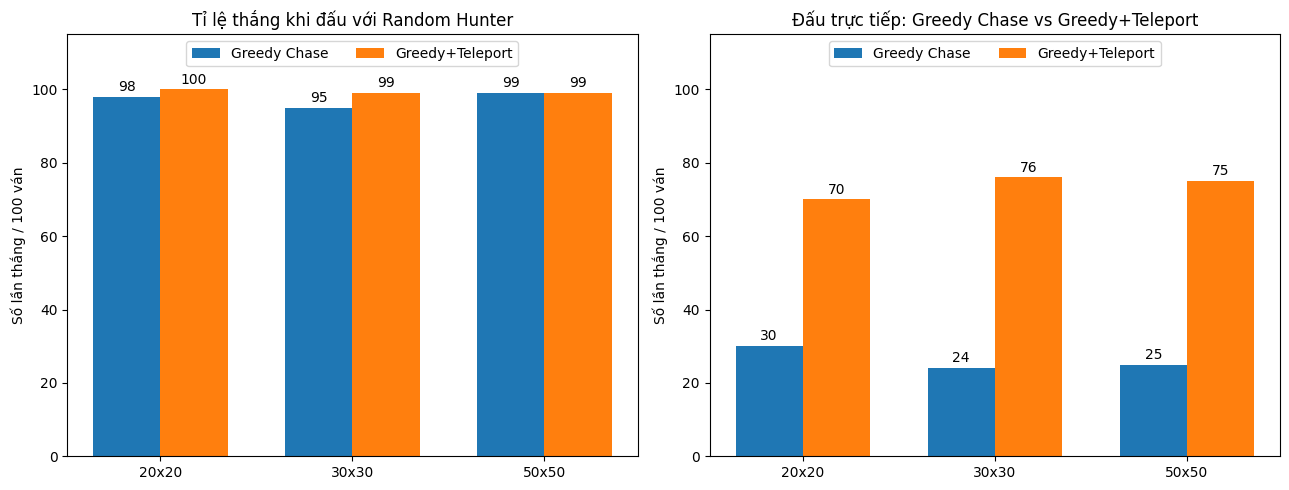

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sizes = ["20x20", "30x30", "50x50"]
greedy_vs_random = results_df[results_df["Đấu"] == "Greedy Chase vs Random"]["Hunter 1 thắng"].values
teleport_vs_random = results_df[results_df["Đấu"] == "Greedy+Teleport vs Random"]["Hunter 1 thắng"].values

x = np.arange(len(sizes))
width = 0.35
axes[0].bar(x - width/2, greedy_vs_random, width, label="Greedy Chase")
axes[0].bar(x + width/2, teleport_vs_random, width, label="Greedy+Teleport")
axes[0].set_xticks(x)
axes[0].set_xticklabels(sizes)
axes[0].set_ylabel("Số lần thắng / 100 ván")
axes[0].set_title("Tỉ lệ thắng khi đấu với Random Hunter")
axes[0].legend(loc="upper center", ncol=2)
axes[0].set_ylim(0, 115)

h2h = results_df[results_df["Đấu"] == "Greedy Chase vs Greedy+Teleport"]
axes[1].bar(x - width/2, h2h["Hunter 1 thắng"].values, width, label="Greedy Chase")
axes[1].bar(x + width/2, h2h["Hunter 2 thắng"].values, width, label="Greedy+Teleport")
axes[1].set_xticks(x)
axes[1].set_xticklabels(sizes)
axes[1].set_ylabel("Số lần thắng / 100 ván")
axes[1].set_title("Đấu trực tiếp: Greedy Chase vs Greedy+Teleport")
axes[1].legend(loc="upper center", ncol=2)
axes[1].set_ylim(0, 115)

for ax in axes:
    for cont in ax.containers:
        ax.bar_label(cont, padding=2)

plt.tight_layout()
plt.savefig("results_chart.png", dpi=120)
plt.show()


### Nhận xét kết quả

Bảng và biểu đồ trên tổng hợp 9 cấu hình × 100 ván (mỗi cấu hình chạy một lần, không cố định seed, `max_steps = 100`).

* **Đấu với Random Hunter.** Greedy Chase thắng 98 / 95 / 99 ván và Greedy+Teleport thắng 100 / 99 / 99 ván ở 20×20 / 30×30 / 50×50. Quái vật không thắng ván nào ở cả 9 cấu hình. Những ván thua hiếm hoi (tối đa 5/100) là do hunter ngẫu nhiên may mắn, ví dụ xuất phát rất gần quái vật.
* **Số bước trung bình để bắt quái vật.** Greedy Chase cần 14.06 / 20.09 / 32.02 bước, còn Greedy+Teleport chỉ cần 8.78 / 11.58 / 17.38 bước, tức nhanh hơn 38% / 42% / 46%: đấu trường càng lớn thì teleport càng có lợi về tốc độ.
* **Đấu trực tiếp.** Greedy+Teleport thắng 70 / 76 / 75 ván (Greedy Chase thắng 30 / 24 / 25). Số bước trung bình ở các ván này thấp hơn (7.96 / 10.87 / 16.58) vì đó là thời gian của hunter nhanh hơn trong hai hunter.
* **Độ tin cậy.** Mỗi cấu hình chỉ có 100 ván nên tỉ lệ thắng có sai số khoảng ±9 điểm phần trăm (khoảng tin cậy 95%). Vì vậy chênh lệch 70 / 76 / 75 giữa ba kích thước chưa đủ để kết luận về một xu hướng; điều chắc chắn là Greedy+Teleport thắng trên 50% ở cả ba kích thước. Ngoài ra, nếu hai hunter cùng chạm quái vật trong một bước thì Hunter 1 (Greedy Chase) được tính thắng trước, nên phép đo hơi nghiêng có lợi cho Greedy Chase.

## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

> **Chiến lược cuối cùng của tôi (Strategy 2: Greedy Chase với Threshold Teleport).** Ở mỗi bước hunter chỉ dựa vào percept hiện tại (vị trí của mình và vị trí quái vật): (1) tính khoảng cách Manhattan $d$ tới quái vật; (2) nếu $d > n/2$ thì `teleport`; (3) ngược lại đi một ô theo trục có chênh lệch lớn hơn. Đây là simple reflex agent: không cần bộ nhớ hay mô hình nội bộ vì môi trường cho quan sát đầy đủ (PEAS – Sensors).
>
> Chiến lược hoạt động tốt vì mỗi bước đi bộ giảm khoảng cách Manhattan đúng 1 ô nên hunter không lãng phí bước nào, trong khi quái vật không hề né tránh và đứng yên 50% thời gian. Vì vậy số bước để bắt quái vật xấp xỉ khoảng cách ban đầu, có kỳ vọng ≈ 2n/3: 12.6 / 19.3 / 32.7 bước cho n = 20 / 30 / 50 (bảng phân tích ở trên). Con số này khớp với kết quả đo của Greedy Chase (14.06 / 20.09 / 32.02), tức số bước tăng gần tuyến tính theo kích thước đấu trường chứ không hỗn loạn như hunter ngẫu nhiên.
>
> **Về teleport.** Tôi có dùng teleport, nhưng chỉ khi $d > n/2$. Đi bộ tốn $d$ bước, còn teleport tốn 1 bước rồi "gieo lại" khoảng cách. Ngay lúc xuất phát, xác suất hunter đã ở xa hơn n/2 là 60 / 62 / 63% (n = 20 / 30 / 50), nên teleport thường được kích hoạt ngay từ những bước đầu. Kết quả: số bước trung bình giảm 38–46% so với chỉ đi bộ và thắng 70–76% số ván đấu trực tiếp.
>
> Teleport có hại trong hai tình huống: (a) khi hunter đã ở gần ($d \le n/2$), vì khoảng cách kỳ vọng sau teleport (≈ 2n/3 với vị trí quái vật bất kỳ) lớn hơn khoảng cách hiện tại nên hunter chỉ mất tiến độ; (b) khi quái vật ở gần góc, vì khoảng cách kỳ vọng sau teleport ≈ 0.9n và chỉ khoảng 15–18% khả năng rơi vào vùng ≤ n/2. Ngưỡng n/2 cố định chưa xét vị trí quái vật; có thể chỉnh tham số `teleport_threshold_ratio` để cải thiện (tôi chưa thử trong bài này).
>
> **Ảnh hưởng của kích thước đấu trường.** Số bước trung bình tăng gần tuyến tính theo n (Greedy Chase: 14.06 / 20.09 / 32.02 bước, tức khoảng 0.64–0.70·n) vì khoảng cách ban đầu tăng theo n. Tỉ lệ thắng trước Random Hunter gần như không đổi (95–100/100) vì quái vật không chạy trốn và `max_steps = 100` vẫn dư (ở 50×50 chỉ cần khoảng 32 bước); nếu n tăng rất lớn thì giới hạn 100 bước sẽ thành nút thắt (ước tính n ≈ 150 với Greedy Chase, chưa kiểm chứng). Lợi thế của teleport tăng theo n: mức giảm số bước là 38% → 42% → 46%, vì đi bộ trên bản đồ lớn tốn nhiều lượt hơn còn teleport chỉ tốn 1 lượt.

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

> Hiện tại quái vật gần như di chuyển ngẫu nhiên và không hề phản ứng với vị trí
> của hai hunter (hàm `monster_agent_function_simple` không dùng `hunter_1_pos`,
> `hunter_2_pos` mặc dù các tham số này đã được truyền vào). Để quái vật "giỏi"
> hơn trong việc né hunter, có thể sửa hàm agent của quái vật thành một **tác tử
> phản xạ dựa trên mô hình** đơn giản:
> - Tính khoảng cách (hoặc hướng) từ quái vật tới hunter gần nhất trong số hai
>   hunter.
> - Nếu khoảng cách đó nhỏ hơn một ngưỡng nguy hiểm, chọn hành động di chuyển
>   theo hướng **ngược lại** với hunter gần nhất (thay vì chọn ngẫu nhiên), để
>   chủ động tăng khoảng cách.
> - Nếu không có hunter nào ở gần, giữ hành vi ngẫu nhiên/đứng yên như hiện tại
>   để tránh vô tình di chuyển thẳng vào một hunter khác.
> - Có thể thêm một xác suất nhỏ để thỉnh thoảng vẫn chọn ngẫu nhiên (giống như
>   $\epsilon$-greedy), để hành vi của quái vật không trở nên hoàn toàn có thể
>   đoán trước được và bị hunter khai thác.
> - Giới hạn tốc độ: quái vật chỉ nên đi tối đa 1 ô mỗi bước (bằng hunter) và vẫn giữ một xác suất đứng yên/ngẫu nhiên; nếu quá nhanh hoặc né quá hoàn hảo thì hunter sẽ không bắt được trong `max_steps`.

## Từ môi trường cạnh tranh sang môi trường hợp tác

*(Theo yêu cầu của đề bài: "Đề xuất cách biến môi trường cạnh tranh thành môi
trường hợp tác, ví dụ chia sẻ thông tin vị trí quái vật giữa hai thợ săn.")*

> Hiện tại hai hunter **cạnh tranh** và cả hai đều biết vị trí quái vật ở mọi bước (PEAS – Sensors), nên việc "chia sẻ vị trí quái vật" **không mang thêm thông tin** trong phiên bản này. Lợi ích của hợp tác ở đây đến từ việc **phối hợp hành động**: thời gian bắt của cả đội là min(T₁, T₂), mà hai hunter cùng đuổi theo một vị trí thường đi cùng một hướng nên hunter chậm hơn gần như không đóng góp gì. Một số cách cụ thể:
>
> 1. **Chia vùng / bao vây (pincer):** một hunter đuổi trực tiếp (Strategy 1), hunter còn lại đi tới ô ở phía đối diện quái vật so với hunter thứ nhất để chặn đường lui.
> 2. **Hàm thắng chung (shared reward):** tính điểm theo thời gian bắt của cả đội (min(T₁, T₂)) thay vì "ai chạm quái vật trước", để hai hunter cùng tối ưu một mục tiêu.
> 3. **Giao tiếp qua hành động "shout":** mở rộng môi trường để một hunter gửi thông điệp (ví dụ hướng đang tiếp cận) cho hunter kia nhằm tránh trùng lặp.
> 4. **Chia sẻ trạng thái nội bộ qua một class dùng chung:** hai hàm agent là hai phương thức của cùng một class và đọc/ghi chung một biến trạng thái (ví dụ vai trò "đuổi" và "chặn").
>
> Nếu môi trường chỉ cho quan sát **một phần** (ví dụ như bài GridHunt đơn tác tử, chỉ biết vị trí quái vật sau hành động `listen`), thì chia sẻ vị trí quái vật mới thực sự có giá trị: một lần `listen` của một hunter giúp cả hai biết vị trí, làm giảm gần một nửa số lần phải `listen`.

# More Work (optional)

* Improve the monster agent so it tries to run away from the hunters. Don;t make the monster too fast or the hunters will never be able to catch it.
* How could the two hunter agents work together? You need to think about information sharing. This can be implemented by the two agent functions sharing a single Python class or the environment could be expanded by an action "shout" that lets the other agent perceive a message.